In [1]:
import pandas, sklearn.preprocessing, sklearn.neighbors, matplotlib.pyplot, pickle

In [2]:
dataframe = pandas.read_csv("data/crop_dataset.csv")
dataframe

,Unnamed: 0,N,Fe,Mn,S,Mg,C,P,K,temperature,humidity,ph,rainfall,label
0,0,90.00000,22.874002,1755.781061,0.478917,99.434611,250.041878,42.0000,43.0000,20.879744,82.002744,6.502985,202.935536,rice
1,1,89.84375,27.877571,1225.577971,9.492673,122.533950,269.432338,42.5000,42.9375,20.907579,81.950147,6.519708,203.676786,rice
2,2,89.68750,29.953866,1652.877830,11.792660,28.923411,243.405980,43.0000,42.8750,20.935414,81.897550,6.536430,204.418036,rice
3,3,89.53125,20.349620,429.346744,13.593830,104.724820,224.334778,43.5000,42.8125,20.963249,81.844954,6.553152,205.159286,rice
4,4,89.37500,25.667180,1117.904838,6.952989,90.663107,240.262857,44.0000,42.7500,20.991083,81.792357,6.569874,205.900536,rice
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69713,3164,105.62500,25.363184,83.085947,4.418164,141.585259,259.765703,19.7500,30.5000,23.936691,59.362840,6.777203,139.216823,coffee
69714,3165,105.21875,27.265318,1238.304455,12.416972,27.629203,266.350916,19.3125,30.3750,23.853272,59.621248,6.777860,139.646878,coffee
69715,3166,104.81250,27.457146,1424.860030,13.230450,115.071609,215.048308,18.8750,30.2500,23.769853,59.879657,6.778518,140.076932,coffee
69716,3167,104.40625,22.176982,260.786061,17.511177,57.416916,297.442290,18.4375,30.1250,23.686435,60.138066,6.779175,140.506987,coffee


In [3]:
dataframe = dataframe.drop([dataframe.columns[0]], axis=1)
dataframe

,N,Fe,Mn,S,Mg,C,P,K,temperature,humidity,ph,rainfall,label
0,90.00000,22.874002,1755.781061,0.478917,99.434611,250.041878,42.0000,43.0000,20.879744,82.002744,6.502985,202.935536,rice
1,89.84375,27.877571,1225.577971,9.492673,122.533950,269.432338,42.5000,42.9375,20.907579,81.950147,6.519708,203.676786,rice
2,89.68750,29.953866,1652.877830,11.792660,28.923411,243.405980,43.0000,42.8750,20.935414,81.897550,6.536430,204.418036,rice
3,89.53125,20.349620,429.346744,13.593830,104.724820,224.334778,43.5000,42.8125,20.963249,81.844954,6.553152,205.159286,rice
4,89.37500,25.667180,1117.904838,6.952989,90.663107,240.262857,44.0000,42.7500,20.991083,81.792357,6.569874,205.900536,rice
...,...,...,...,...,...,...,...,...,...,...,...,...,...
69713,105.62500,25.363184,83.085947,4.418164,141.585259,259.765703,19.7500,30.5000,23.936691,59.362840,6.777203,139.216823,coffee
69714,105.21875,27.265318,1238.304455,12.416972,27.629203,266.350916,19.3125,30.3750,23.853272,59.621248,6.777860,139.646878,coffee
69715,104.81250,27.457146,1424.860030,13.230450,115.071609,215.048308,18.8750,30.2500,23.769853,59.879657,6.778518,140.076932,coffee
69716,104.40625,22.176982,260.786061,17.511177,57.416916,297.442290,18.4375,30.1250,23.686435,60.138066,6.779175,140.506987,coffee


In [4]:
dataframe.info()

<class 'pandas.DataFrame'>
RangeIndex: 69718 entries, 0 to 69717
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            69718 non-null  float64
 1   Fe           69718 non-null  float64
 2   Mn           69718 non-null  float64
 3   S            69718 non-null  float64
 4   Mg           69718 non-null  float64
 5   C            69718 non-null  float64
 6   P            69718 non-null  float64
 7   K            69718 non-null  float64
 8   temperature  69718 non-null  float64
 9   humidity     69718 non-null  float64
 10  ph           69718 non-null  float64
 11  rainfall     69718 non-null  float64
 12  label        69718 non-null  str    
dtypes: float64(12), str(1)
memory usage: 6.9 MB


In [5]:
dataframe.describe()

,N,Fe,Mn,S,Mg,C,P,K,temperature,humidity,ph,rainfall
count,69718.00000,69718.000000,69718.000000,69718.000000,69718.000000,69718.000000,69718.000000,69718.000000,69718.000000,69718.000000,69718.000000,69718.000000
mean,50.53654,25.005211,1020.186919,9.976035,75.337975,249.981793,53.337151,48.150327,25.621811,71.482363,6.470961,103.451243
std,36.24012,2.887917,577.435205,5.779192,43.657424,29.007222,32.719135,50.609850,4.647055,22.146670,0.689248,53.601999
min,0.00000,20.000167,20.001386,0.000182,0.002380,200.000325,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.06250,22.508051,519.760125,4.948271,37.562911,224.783150,26.656250,20.250000,22.796805,60.001913,6.005493,66.008289
50%,35.12500,25.014980,1017.642830,9.984787,75.247649,250.171788,50.156250,31.468750,25.627236,80.727621,6.442027,95.397009
75%,85.25000,27.513380,1521.726212,14.982861,113.355749,275.247817,67.875000,49.000000,28.497029,90.085664,6.877140,126.324563
max,140.00000,29.999714,2019.983290,19.999238,150.995672,299.998857,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


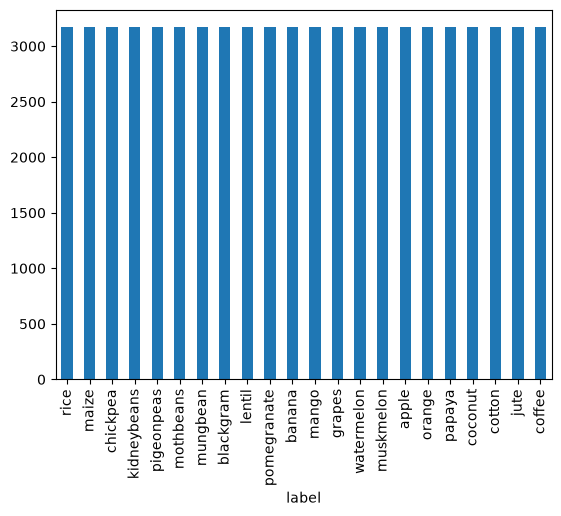

In [6]:
dataframe[dataframe.columns[-1]].value_counts().plot(kind="bar")
matplotlib.pyplot.show()

In [7]:
training_data = dataframe[["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]]
training_data

,N,P,K,temperature,humidity,ph,rainfall
0,90.00000,42.0000,43.0000,20.879744,82.002744,6.502985,202.935536
1,89.84375,42.5000,42.9375,20.907579,81.950147,6.519708,203.676786
2,89.68750,43.0000,42.8750,20.935414,81.897550,6.536430,204.418036
3,89.53125,43.5000,42.8125,20.963249,81.844954,6.553152,205.159286
4,89.37500,44.0000,42.7500,20.991083,81.792357,6.569874,205.900536
...,...,...,...,...,...,...,...
69713,105.62500,19.7500,30.5000,23.936691,59.362840,6.777203,139.216823
69714,105.21875,19.3125,30.3750,23.853272,59.621248,6.777860,139.646878
69715,104.81250,18.8750,30.2500,23.769853,59.879657,6.778518,140.076932
69716,104.40625,18.4375,30.1250,23.686435,60.138066,6.779175,140.506987


In [8]:
scaler = sklearn.preprocessing.StandardScaler()
scaler

,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [9]:
training_data = pandas.DataFrame(scaler.fit_transform(training_data), columns=training_data.columns, index=training_data.index)
training_data

,N,P,K,temperature,humidity,ph,rainfall
0,1.088952,-0.346502,-0.101766,-1.020453,0.475036,0.046464,1.855994
1,1.084640,-0.331220,-0.103001,-1.014463,0.472661,0.070725,1.869823
2,1.080329,-0.315938,-0.104236,-1.008473,0.470286,0.094987,1.883652
3,1.076017,-0.300657,-0.105471,-1.002483,0.467911,0.119249,1.897481
4,1.071706,-0.285375,-0.106706,-0.996494,0.465536,0.143510,1.911310
...,...,...,...,...,...,...,...
69713,1.520107,-1.026537,-0.348755,-0.362624,-0.547243,0.444316,0.667248
69714,1.508897,-1.039908,-0.351225,-0.380575,-0.535575,0.445270,0.675271
69715,1.497687,-1.053280,-0.353695,-0.398526,-0.523907,0.446224,0.683295
69716,1.486477,-1.066651,-0.356165,-0.416477,-0.512239,0.447178,0.691318


In [10]:
model = sklearn.neighbors.NearestNeighbors(metric="euclidean", n_neighbors=300, algorithm="auto")
model

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",300
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None


In [11]:
model.fit(training_data)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",300
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"radius radius: float, default=1.0Range of parameter space to use by default for :meth:`radius_neighbors`queries.",1.0
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float (positive), default=2Parameter for the Minkowski metric fromsklearn.metrics.pairwise.pairwise_distances. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
effective_metric_ effective_metric_: strMetric used to compute distances to neighbors.,str,'eu...an'
effective_metric_params_ effective_metric_params_: dictParameters for the metric used to compute distances to neighbors.,dict,{}


In [12]:
training_data.columns

Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall'], dtype='str')

In [13]:
example_crop = pandas.DataFrame([{
    "N": 60,
    "P": 45,
    "K": 43,
    "temperature": 26,
    "humidity": 80,
    "ph": 6.8,
    "rainfall": 196
}])

example_crop

,N,P,K,temperature,humidity,ph,rainfall
0,60,45,43,26,80,6.8,196


In [14]:
example_crop = pandas.DataFrame(scaler.transform(example_crop), columns=example_crop.columns, index=example_crop.index)
example_crop

,N,P,K,temperature,humidity,ph,rainfall
0,0.261134,-0.254811,-0.101766,0.081383,0.384604,0.477392,1.726604


In [15]:
dataframe.iloc[model.kneighbors(example_crop, n_neighbors=300, return_distance=False)[0]]["label"].value_counts().index.to_list()

['jute', 'rice', 'papaya']

In [16]:
with open("models/crop_recommendation_model.pickle", "wb+") as file:
    pickle.dump((scaler, training_data.columns, dataframe["label"].to_numpy(), model), file)